In [37]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore", message="Workbook contains no default style")

raw = pd.read_excel("SeriesReport-20261019050857_3cedaf.xlsx",
                    sheet_name="BLS Data Series", skiprows=3)

# 2. FIPS → 州名 映射
fips_to_state = {
    '01':'Alabama','02':'Alaska','04':'Arizona','05':'Arkansas','06':'California',
    '08':'Colorado','09':'Connecticut','10':'Delaware','11':'District of Columbia',
    '12':'Florida','13':'Georgia','15':'Hawaii','16':'Idaho','17':'Illinois',
    '18':'Indiana','19':'Iowa','20':'Kansas','21':'Kentucky','22':'Louisiana',
    '23':'Maine','24':'Maryland','25':'Massachusetts','26':'Michigan','27':'Minnesota',
    '28':'Mississippi','29':'Missouri','30':'Montana','31':'Nebraska','32':'Nevada',
    '33':'New Hampshire','34':'New Jersey','35':'New Mexico','36':'New York',
    '37':'North Carolina','38':'North Dakota','39':'Ohio','40':'Oklahoma',
    '41':'Oregon','42':'Pennsylvania','44':'Rhode Island','45':'South Carolina',
    '46':'South Dakota','47':'Tennessee','48':'Texas','49':'Utah','50':'Vermont',
    '51':'Virginia','53':'Washington','54':'West Virginia','55':'Wisconsin','56':'Wyoming'
}

# 3. 提取州码，过滤（51个地区）
raw['fips'] = raw['Series ID'].astype(str).str[5:7]
raw = raw[raw['fips'].isin(fips_to_state)].copy()
raw['state'] = raw['fips'].map(fips_to_state)

# 4. 宽转长
month_cols = [c for c in raw.columns if isinstance(c, str) and '-' not in c and c not in ('Series ID','fips','state')]
long = raw.melt(id_vars=['state'], value_vars=month_cols,
                var_name='date_str', value_name='unemployment_rate')

# 5. 解析日期、数值化、过滤 2000–2025
long['date'] = pd.to_datetime(long['date_str'], format='%b %Y', errors='coerce')
long['unemployment_rate'] = pd.to_numeric(long['unemployment_rate'], errors='coerce')
long = long.dropna(subset=['date','unemployment_rate'])
long = long[(long['date'].dt.year >= 2000) & (long['date'].dt.year <= 2025)]
long['year'] = long['date'].dt.year

# 6. 聚合到 state-year 面板（年均失业率）
panel = (long.groupby(['state','year'], as_index=False)
              ['unemployment_rate'].mean()
              .rename(columns={'unemployment_rate':'unemp_rate'}))


state_year_matrix = panel.pivot(index='state', columns='year', values='unemp_rate')

panel.to_csv("state_unemployment_panel.csv", index=False)
print(panel.shape)   # 约 (51*15, 3) = (765, 3)

(1326, 3)


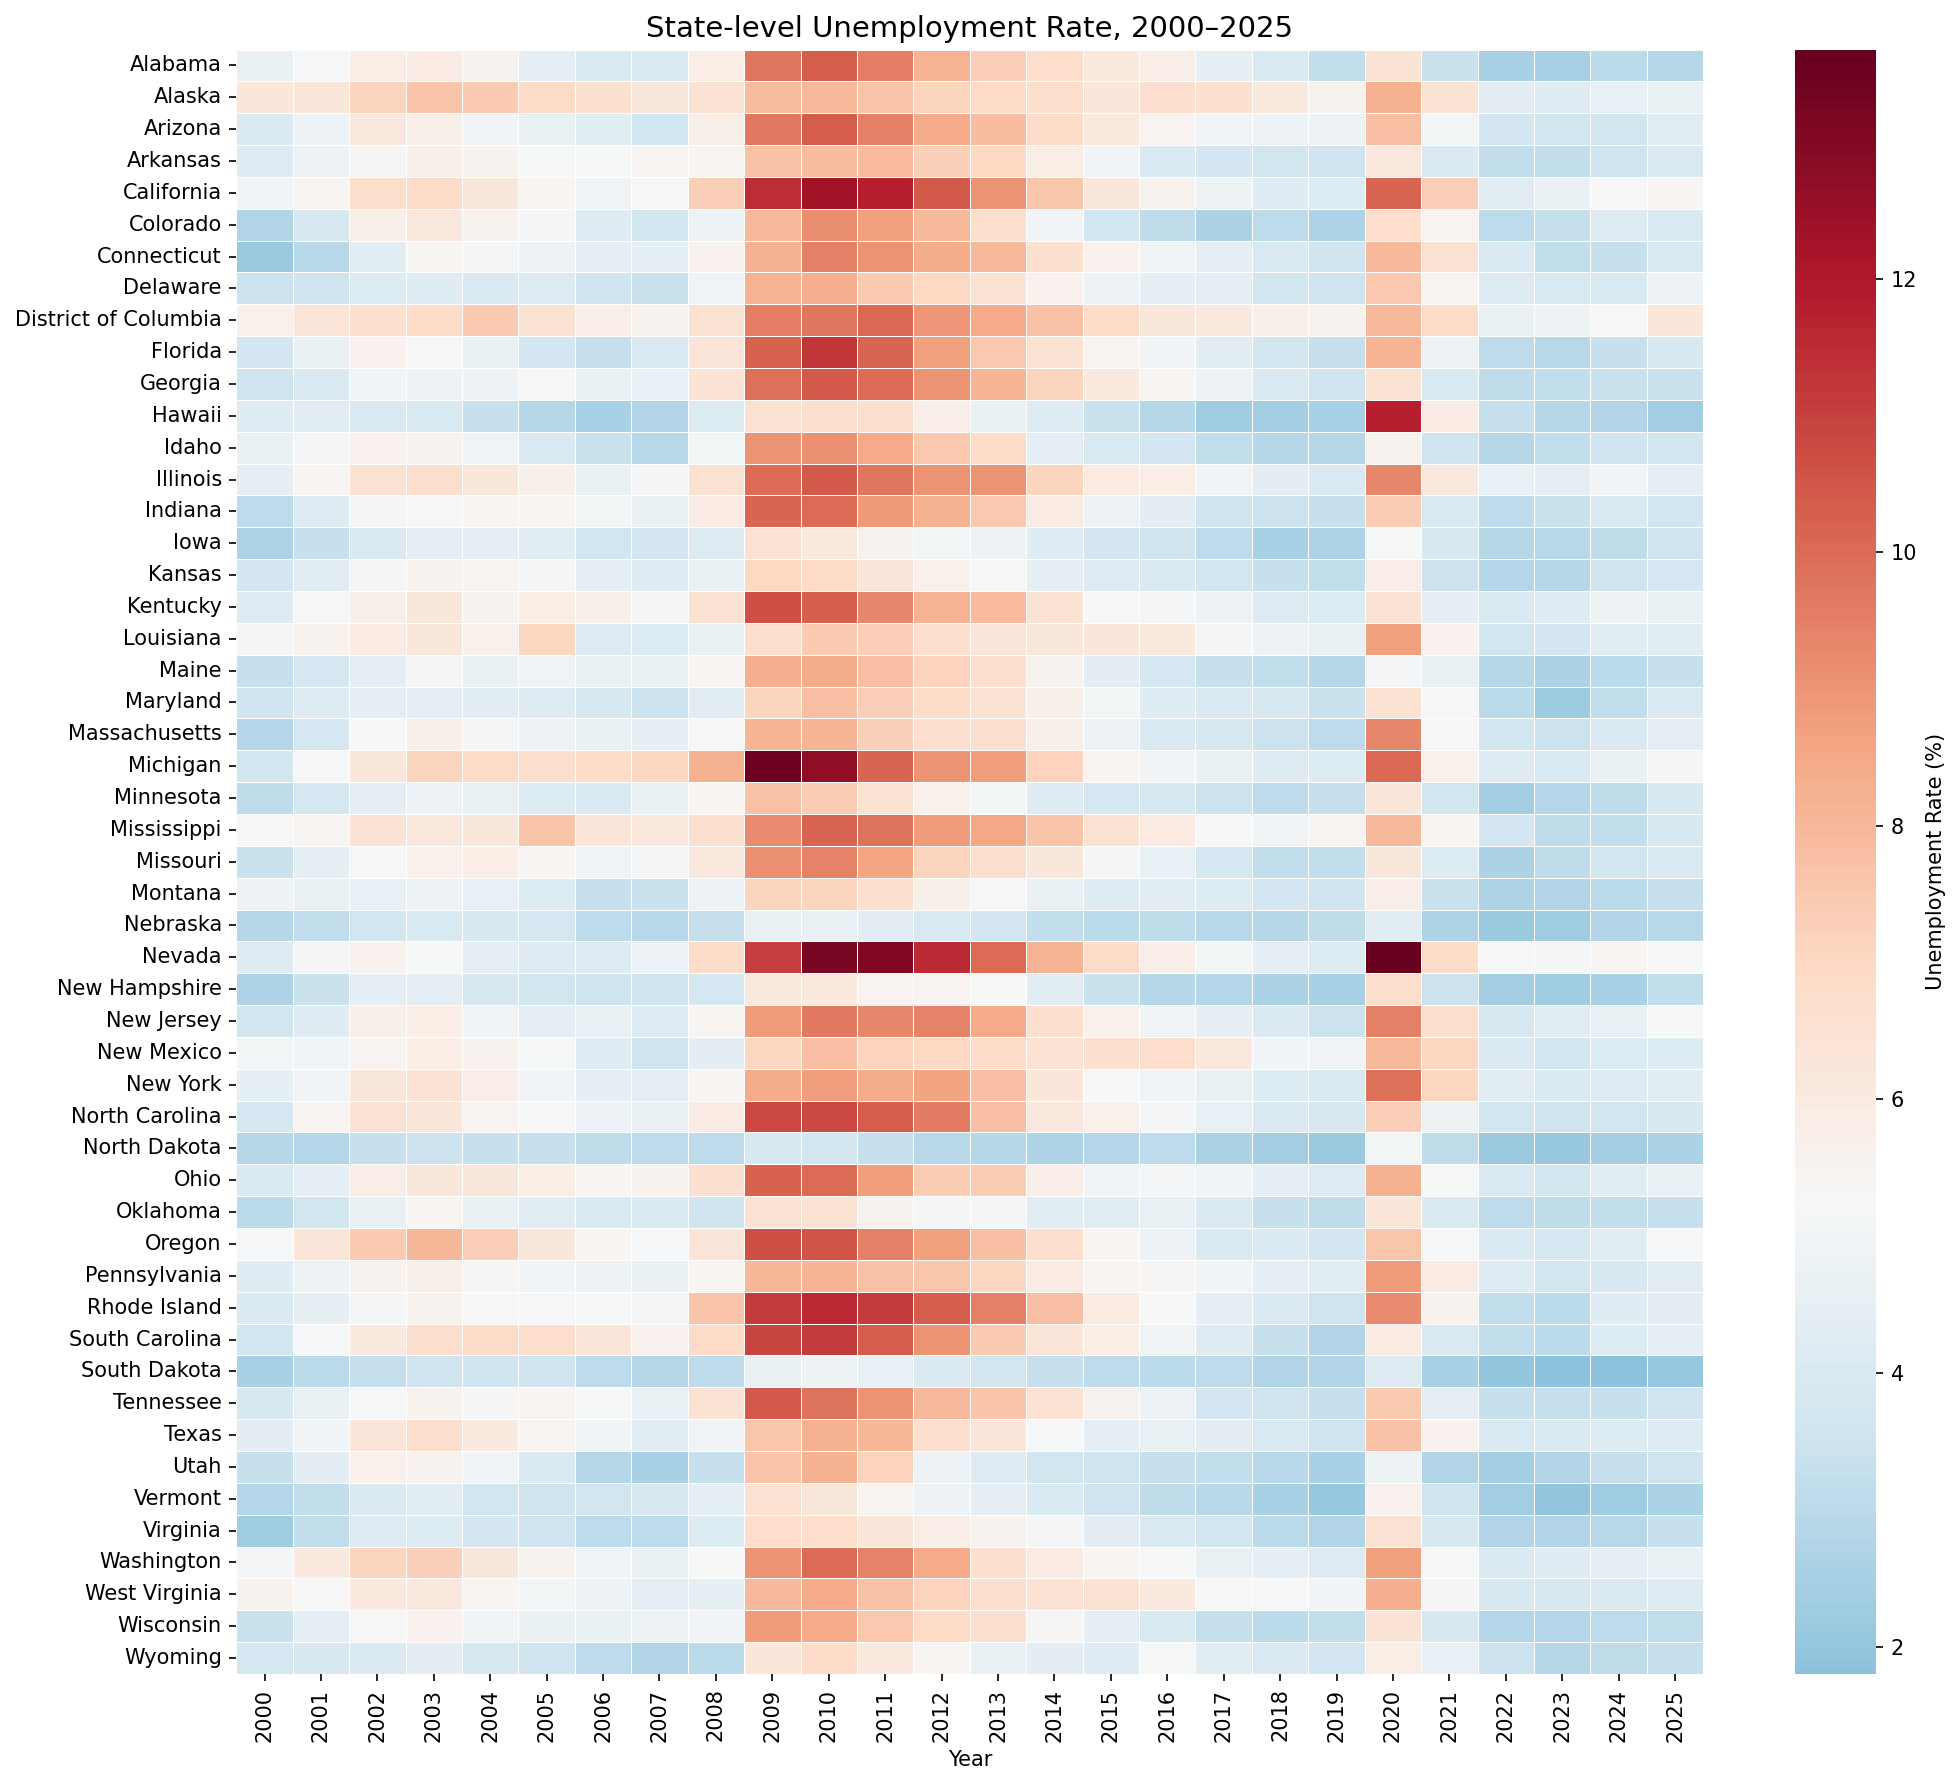

In [39]:
##热力图
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 12), dpi=150)
sns.heatmap(state_year_matrix,
            cmap='RdBu_r',          # 红=高失业率，蓝=低
            center=state_year_matrix.values.mean(),
            linewidths=0.3, linecolor='white',
            cbar_kws={'label':'Unemployment Rate (%)'})
plt.title('State-level Unemployment Rate, 2000–2025', fontsize=14)
plt.xlabel('Year'); plt.ylabel('')
plt.tight_layout(); plt.show()

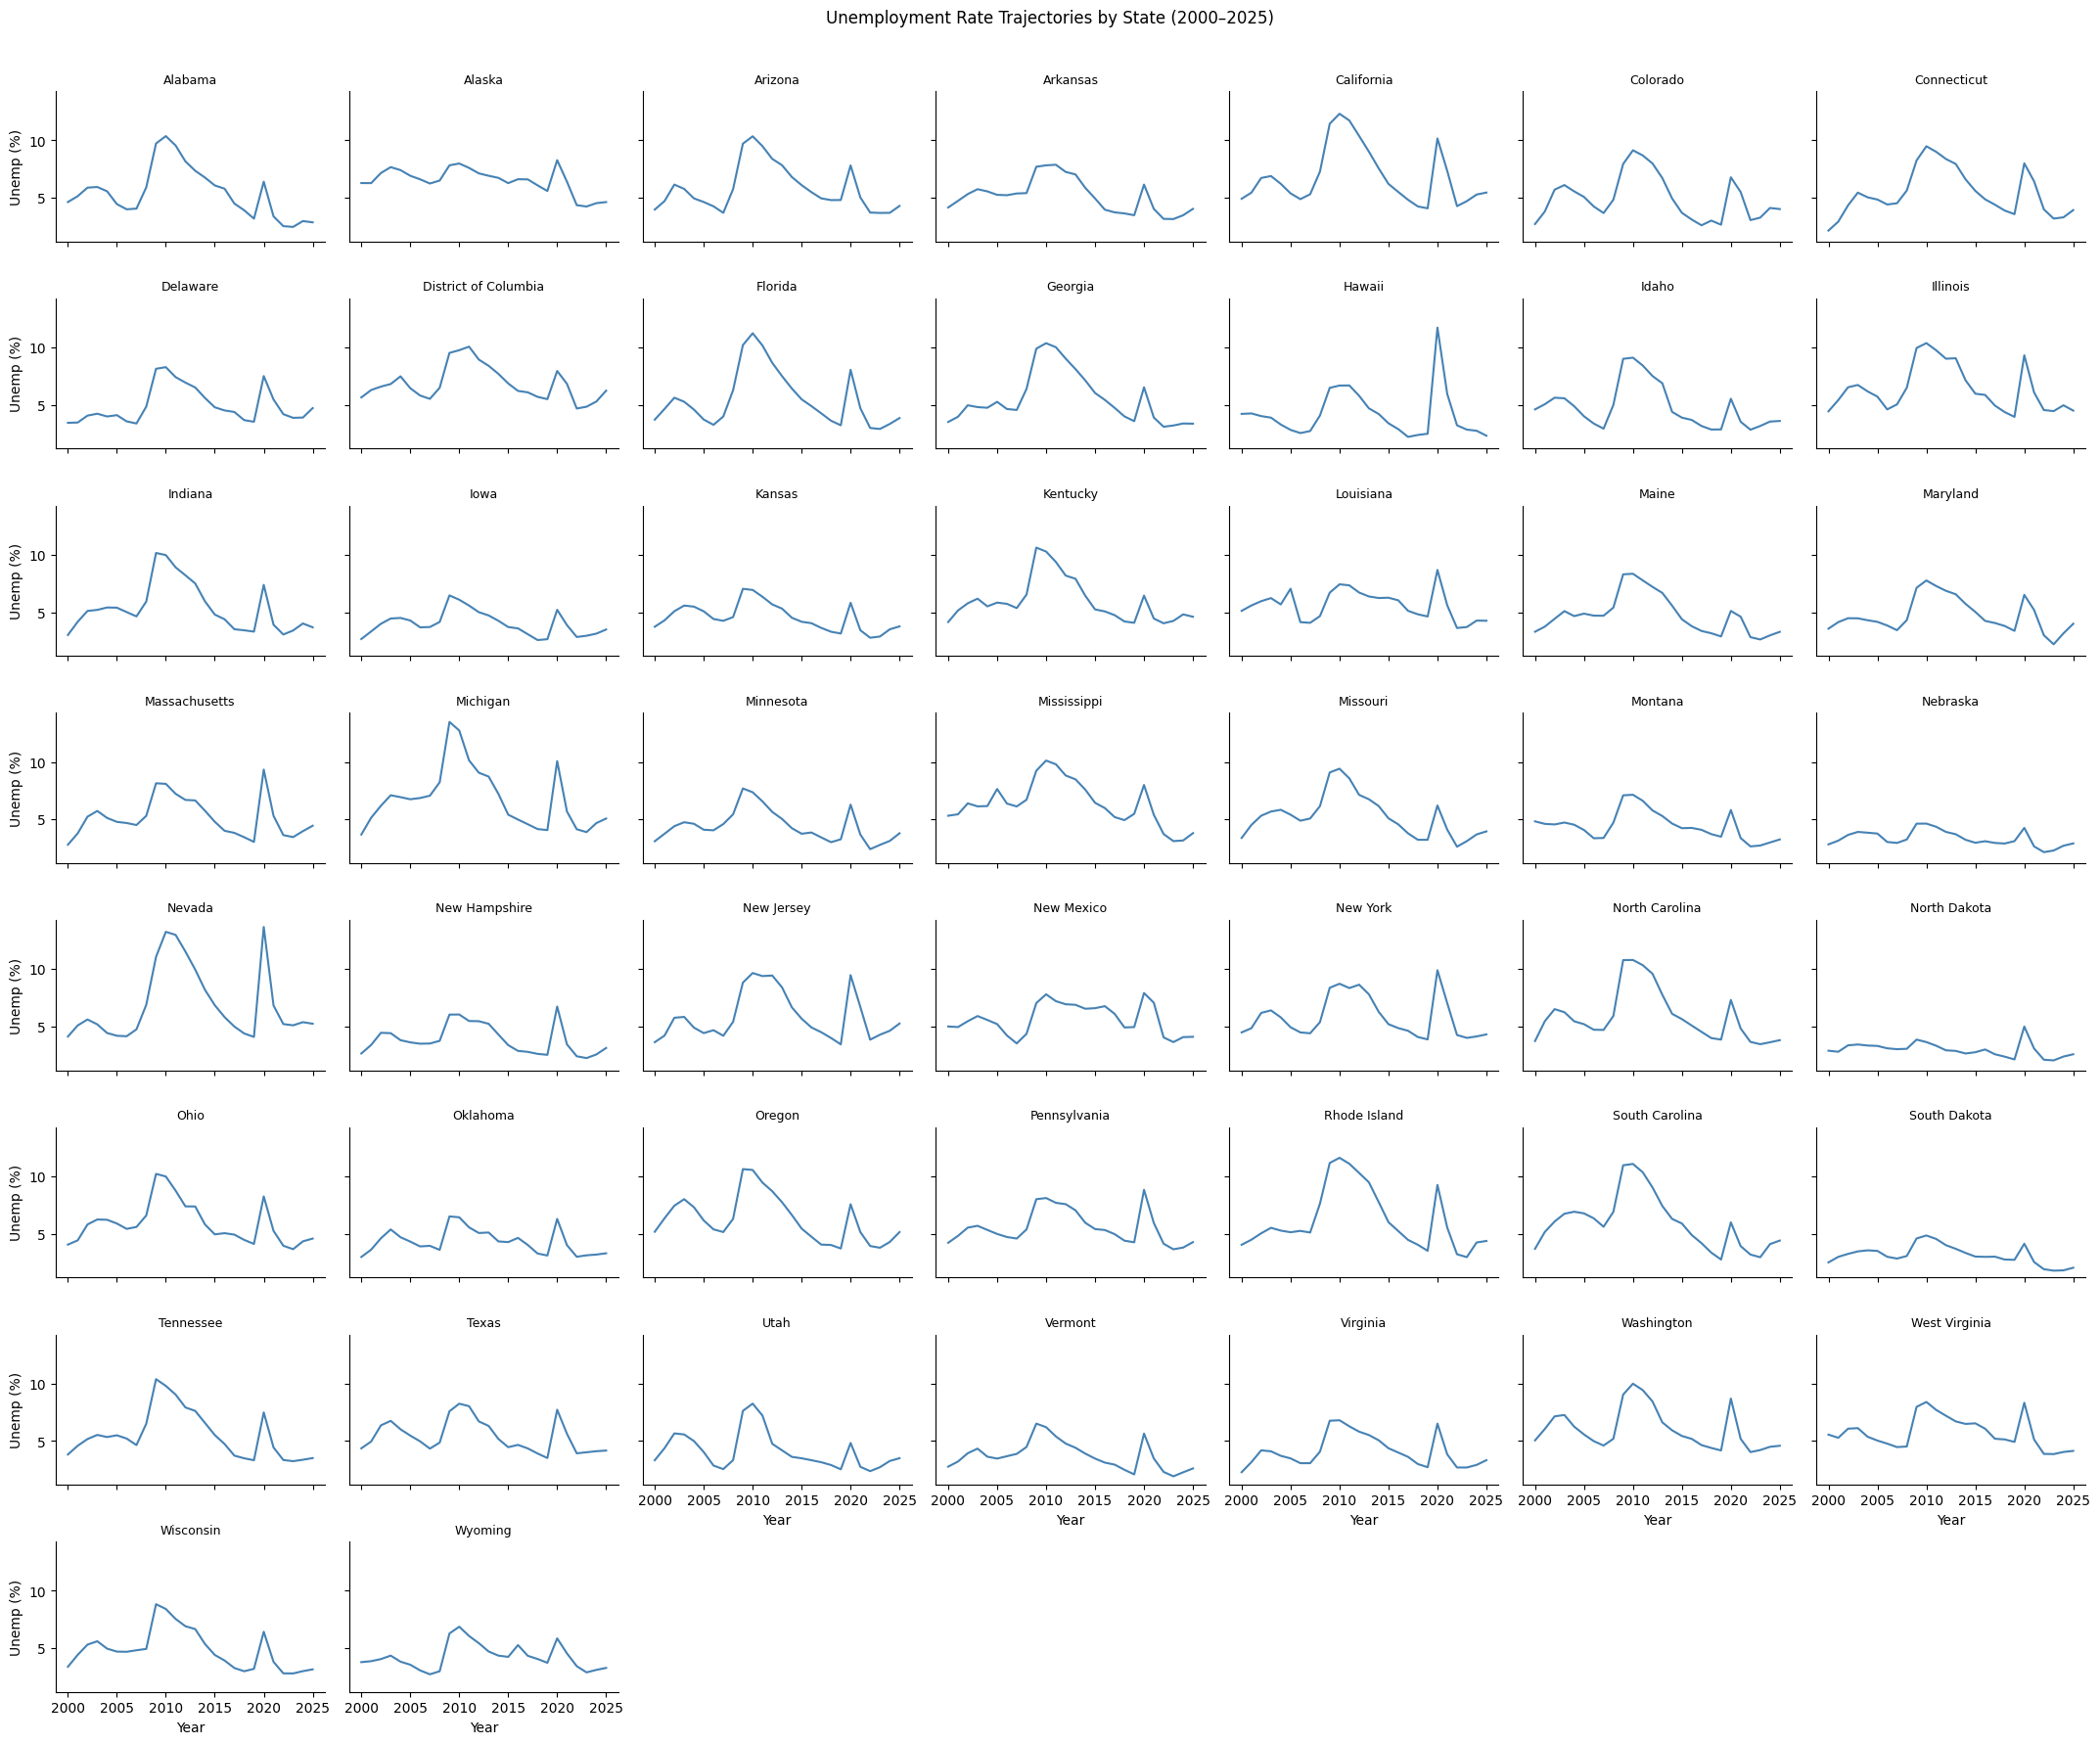

In [40]:
g = sns.FacetGrid(panel, col='state', col_wrap=7,
                  sharey=True, height=2.2, aspect=1.4)
g.map(sns.lineplot, 'year', 'unemp_rate', color='steelblue')
g.set_titles('{col_name}', size=9)
g.set_axis_labels('Year', 'Unemp (%)')
g.fig.suptitle('Unemployment Rate Trajectories by State (2000–2025)', y=1.01)
plt.tight_layout(); plt.show()

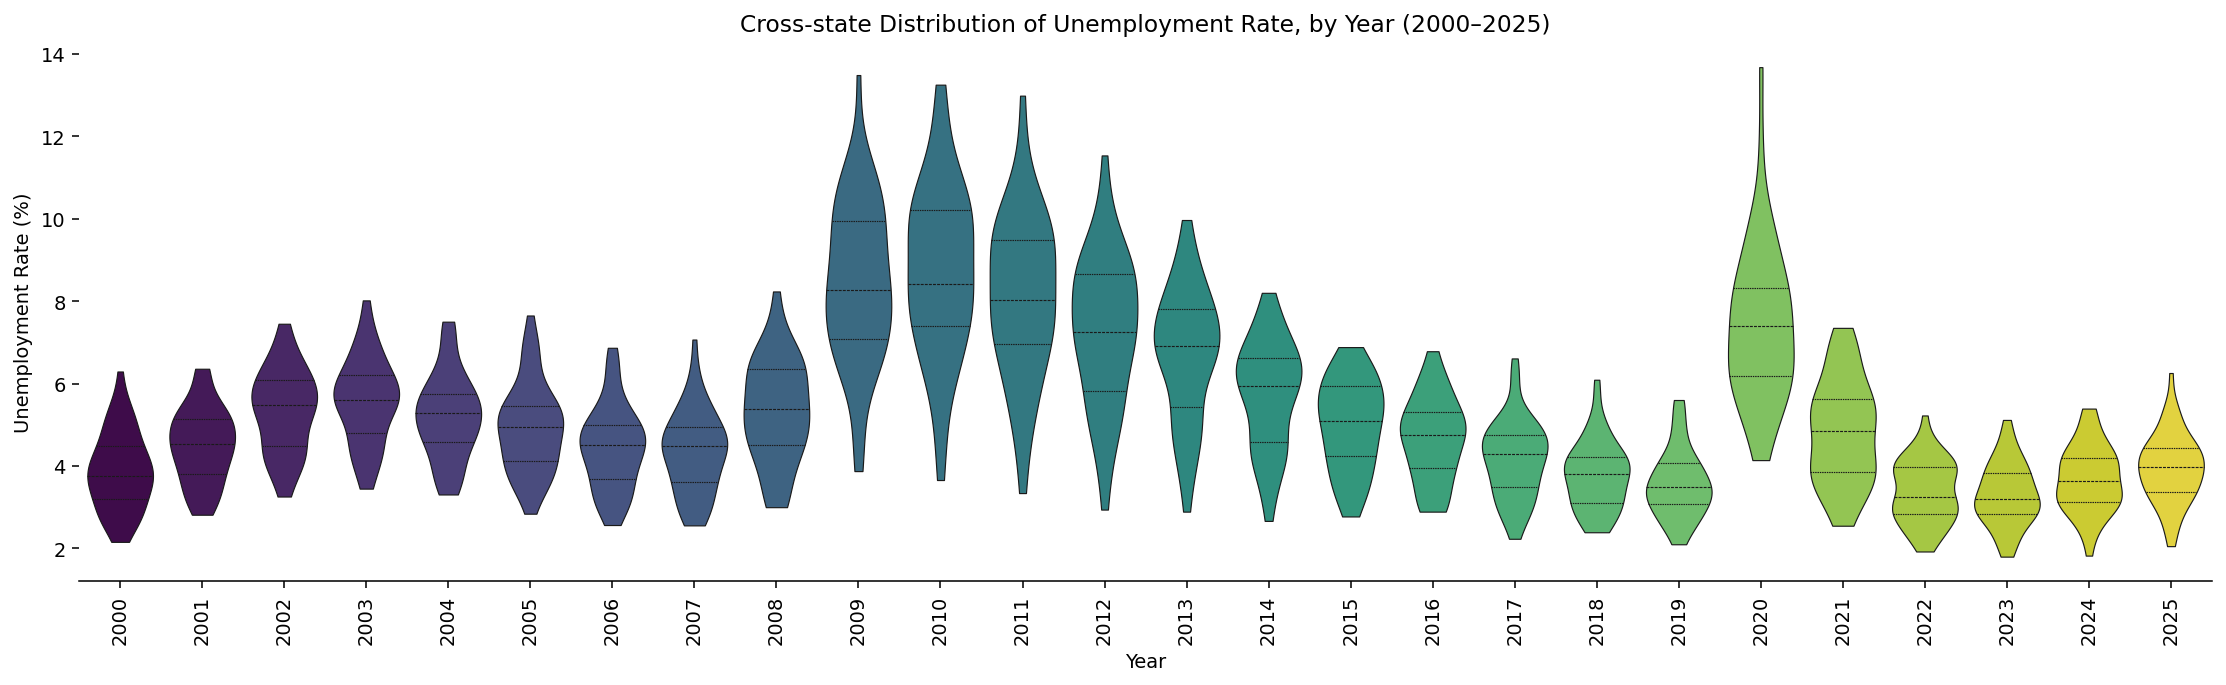

In [43]:
### 小提琴图
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 5), dpi=140)
sns.violinplot(
    data=panel, x="year", y="unemp_rate",
    hue="year", palette="viridis", legend=False,   
    inner="quartile", cut=0, linewidth=0.6
)
plt.title("Cross-state Distribution of Unemployment Rate, by Year (2000–2025)")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=90)
sns.despine(left=True)
plt.tight_layout()
plt.show()

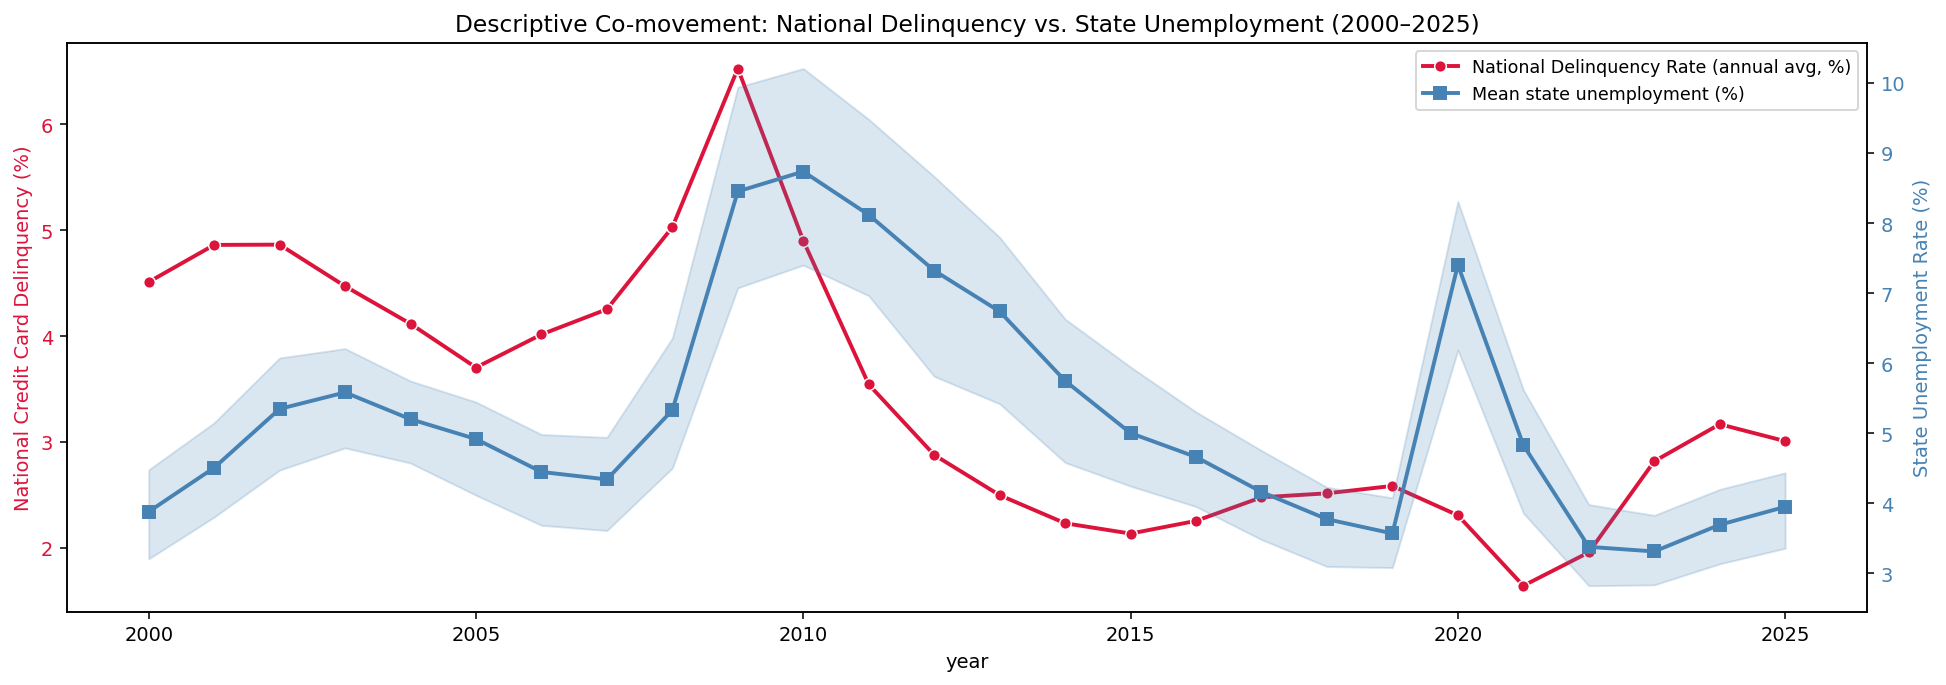

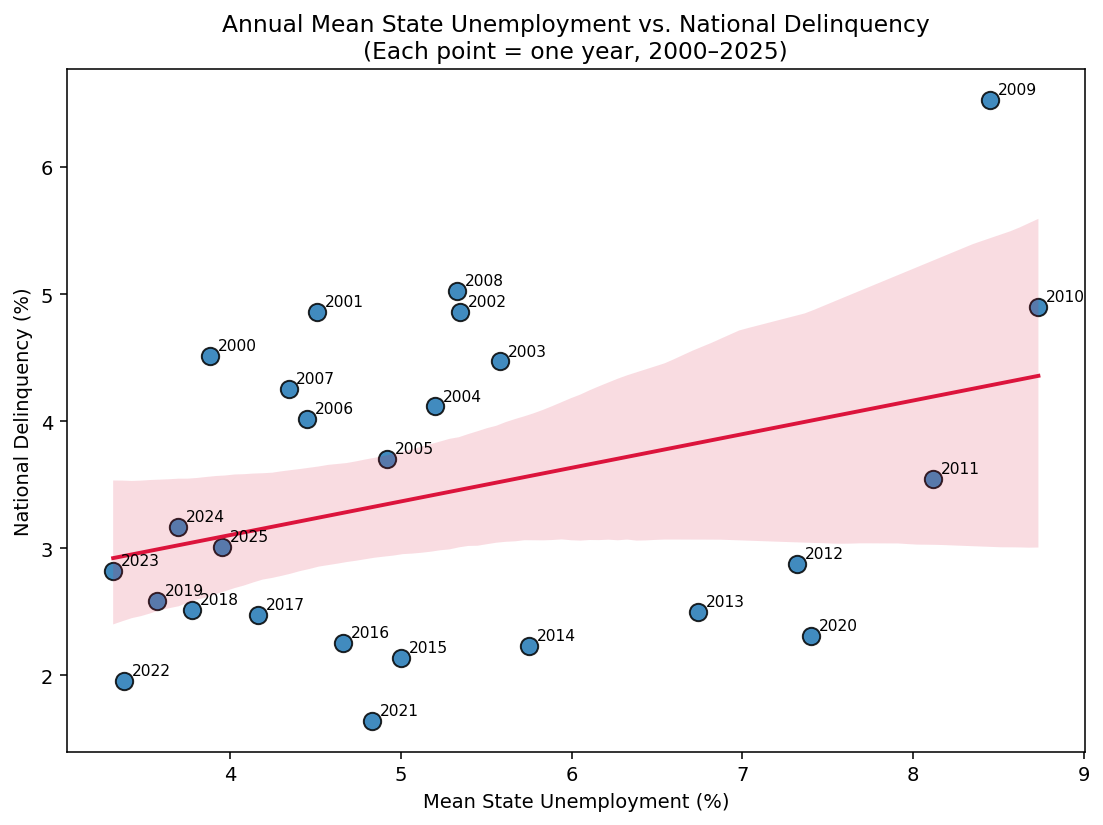

Pearson r (annual): 0.346


In [47]:
# ============================================================
# 数据准备：读取全国拖欠率并合并到州-年面板
# ============================================================
import pandas as pd

# 1. 读取全国信用卡拖欠率（季度数据），按年均值聚合
delinq = pd.read_csv("DRCCLACBS.csv", parse_dates=["observation_date"])
delinq["year"] = delinq["observation_date"].dt.year
national_year = (delinq.groupby("year", as_index=False)
                 .agg(national_delinq_rate=("DRCCLACBS", "mean")))

# 2. 限定分析区间 2000–2025
national_year = national_year[(national_year["year"] >= 2000) &
                              (national_year["year"] <= 2025)]

# 3. 复制 panel 并合并拖欠率
panel_plot = panel.copy()
panel_plot = panel_plot[(panel_plot["year"] >= 2000) &
                        (panel_plot["year"] <= 2025)]
panel_plot = panel_plot.merge(national_year, on="year", how="left")

# ============================================================
# 图 C：双轴共动图 — 全国拖欠率 vs 州际失业率均值/IQR
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax1 = plt.subplots(figsize=(14, 5), dpi=140)

# 左轴：全国拖欠率
sns.lineplot(data=national_year, x="year", y="national_delinq_rate",
             ax=ax1, color="crimson", marker="o", lw=2,
             label="National Delinquency Rate (annual avg, %)")
ax1.set_ylabel("National Credit Card Delinquency (%)", color="crimson")
ax1.tick_params(axis="y", labelcolor="crimson")

# 右轴：州际失业率均值与 IQR
ax2 = ax1.twinx()
yr = panel_plot.groupby("year")["unemp_rate"]
mean_u, q25, q75 = yr.mean(), yr.quantile(.25), yr.quantile(.75)
ax2.fill_between(mean_u.index, q25.values, q75.values,
                 alpha=.2, color="steelblue")
ax2.plot(mean_u.index, mean_u.values, color="steelblue", marker="s", lw=2,
         label="Mean state unemployment (%)")
ax2.set_ylabel("State Unemployment Rate (%)", color="steelblue")
ax2.tick_params(axis="y", labelcolor="steelblue")

# 合并图例
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, loc="upper right", fontsize=9)

plt.title("Descriptive Co-movement: National Delinquency vs. State Unemployment (2000–2025)")
plt.tight_layout()
plt.show()

# ============================================================
# 图 D：年均散点 + regplot
# ============================================================
year_summary = (panel_plot.groupby("year", as_index=False)
                .agg(mean_state_unemp=("unemp_rate", "mean"),
                     national_delinq=("national_delinq_rate", "first"),
                     state_unemp_sd=("unemp_rate", "std")))

plt.figure(figsize=(8, 6), dpi=140)
sns.regplot(data=year_summary, x="mean_state_unemp", y="national_delinq",
            scatter_kws={"s": 80, "alpha": .85, "edgecolor": "k"},
            line_kws={"color": "crimson", "lw": 2})

for _, r in year_summary.iterrows():
    plt.annotate(int(r["year"]),
                 (r["mean_state_unemp"], r["national_delinq"]),
                 textcoords="offset points", xytext=(4, 3), fontsize=8)

plt.title("Annual Mean State Unemployment vs. National Delinquency\n(Each point = one year, 2000–2025)")
plt.xlabel("Mean State Unemployment (%)")
plt.ylabel("National Delinquency (%)")
plt.tight_layout()
plt.show()

print("Pearson r (annual):",
      year_summary["mean_state_unemp"].corr(year_summary["national_delinq"]).round(3))